In [186]:
import sklearn.datasets as datasets
import numpy as np
import matplotlib.pyplot as plt

In [187]:
def MMD_squared(A, B, kernel, gamma):
    def se(A, B, gamma):
        return np.exp(-gamma * np.sum((A[:, np.newaxis, :] - B[np.newaxis, :, :]) ** 2, axis=2))
    
    def imq(A,B, gamma):
        return 1 / np.sqrt(gamma**2 * np.sum((A[:, np.newaxis, :] - B[np.newaxis, :, :]) ** 2, axis=2) + 1)
    
    if kernel == 'se':
        K_XX = se(A, A, gamma)
        K_YY = se(B, B, gamma)
        K_XY = se(A, B, gamma)
    elif kernel == 'imq':
        K_XX = imq(A, A, gamma)
        K_YY = imq(B, B, gamma)
        K_XY = imq(A, B, gamma)
    else:
        raise ValueError("Unsupported kernel. Use 'se' or 'imq'.")

    mmd_squared = np.mean(K_XX) + np.mean(K_YY) - 2 * np.mean(K_XY)
    return mmd_squared




(1000, 2)


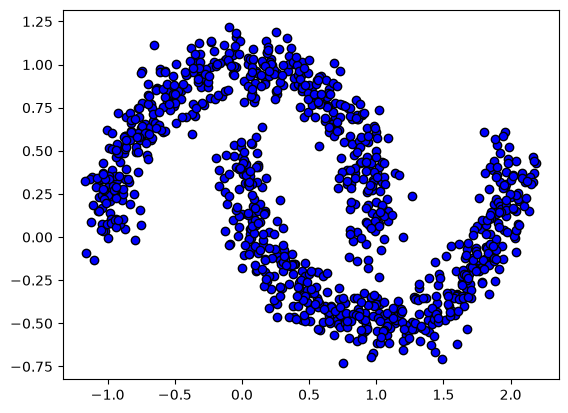

In [188]:
data, _ = datasets.make_moons(n_samples=1000, noise=0.1)

print(data.shape) 
plt.scatter(data[:, 0], data[:, 1], c='blue', edgecolor='k')
plt.show()


In [189]:
class Two_D_histogram:
    def __init__(self, x_bins, y_bins, uniform_sample):
        self.x_bins = x_bins
        self.y_bins = y_bins
        self.histogram = [[0 for _ in range(y_bins)] for _ in range(x_bins)]
        self.uniform_sample = uniform_sample
        self.data = data

    def fit(self):
       

        self.x_edges = np.linspace(np.min(data[:, 0]), np.max(data[:, 0]), self.x_bins + 1)
        self.y_edges = np.linspace(np.min(data[:, 1]), np.max(data[:, 1]), self.y_bins + 1)

        self.histogram, _, _ = np.histogram2d(data[:, 0], data[:, 1], bins=[self.x_edges, self.y_edges])


        self.bin_areas = np.diff(self.x_edges)[:, None] * np.diff(self.y_edges)[None, :]

        self.histogram_probability_density = self.histogram / (np.sum(self.histogram) * self.bin_areas)

        probability_mass = self.histogram / np.sum(self.histogram)
        self.cdf = np.cumsum(probability_mass.flatten())

        self.cdf[-1] = 1.0

        return self
    #sampl
    def sample(self, n_samples):
        uniform_samples = np.random.default_rng().uniform(0, 1, n_samples)
        bin_indices = np.searchsorted(self.cdf, uniform_samples)
        x_indices, y_indices = np.unravel_index(bin_indices, self.histogram.shape)
        x_samples = np.random.uniform(self.x_edges[x_indices], self.x_edges[x_indices + 1])
        y_samples = np.random.uniform(self.y_edges[y_indices], self.y_edges[y_indices + 1])
        return np.column_stack((x_samples, y_samples))  

    def score_samples(self, data):
        x_indices = np.searchsorted(self.x_edges, data[:,0], side='right') - 1
        y_indices = np.searchsorted(self.y_edges, data[:,1], side='right') - 1

        inside = (x_indices >= 0) & (x_indices < self.x_bins) & (y_indices >= 0) & (y_indices < self.y_bins)
        density = np.zeros(data.shape[0])
        density[inside] = self.histogram_probability_density[x_indices[inside], y_indices[inside]]
        return density




    def plot_histogram(self):
        plt.imshow(self.histogram.T, origin='lower', extent=[self.x_edges[0], self.x_edges[-1], self.y_edges[0], self.y_edges[-1]], cmap='viridis', aspect='equal')
        plt.colorbar(label='Count')
        plt.xlabel('X')
        plt.ylabel('Y')
        plt.title('2D Histogram')
        plt.show()





    

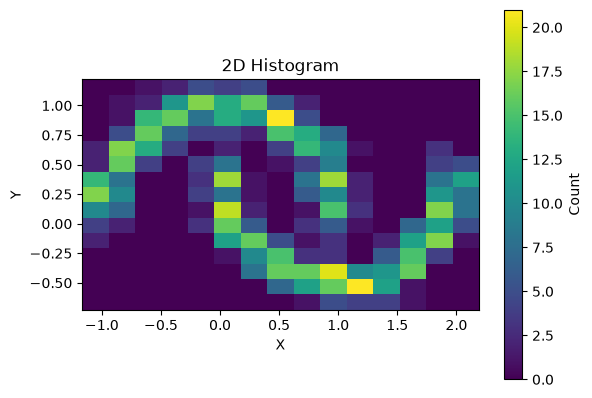

In [190]:
sample_size = 1000
x_bins = 15
y_bins = 15



Two_D_hist = Two_D_histogram(x_bins, y_bins, uniform_sample=True)
Two_D_hist.fit()
Two_D_hist.sample(sample_size)
Two_D_hist.plot_histogram()

In [191]:
class single_Gaussian:
    def __init__(self):
        self.mean = None
        self.covariance = None

    def fit(self, data):
        self.mean = np.mean(data, axis=0)
        self.covariance = np.cov(data, rowvar=False)

    def sample(self, n_samples):
        return np.random.multivariate_normal(self.mean, self.covariance, n_samples)

    def score_samples(self, data):
        diff = data - self.mean
        inv_cov = np.linalg.inv(self.covariance)
        exponent = -0.5 * np.sum(diff @ inv_cov * diff, axis=1)
        normalization = 1 / (np.sqrt((2 * np.pi) ** len(self.mean) * np.linalg.det(self.covariance)))
        density = normalization * np.exp(exponent)
        return density

    def plot_gaussian(self):
        x = np.linspace(np.min(data[:, 0]), np.max(data[:, 0]), 100)
        y = np.linspace(np.min(data[:, 1]), np.max(data[:, 1]), 100)
        X, Y = np.meshgrid(x, y)
        pos = np.dstack((X, Y))
        Z = self.score_samples(pos.reshape(-1, 2)).reshape(X.shape)

        plt.contourf(X, Y, Z, levels=50, cmap='viridis')
        plt.colorbar(label='Density')
        plt.xlabel('X')
        plt.ylabel('Y')
        plt.title('Single Gaussian Density Estimation')
        plt.show()

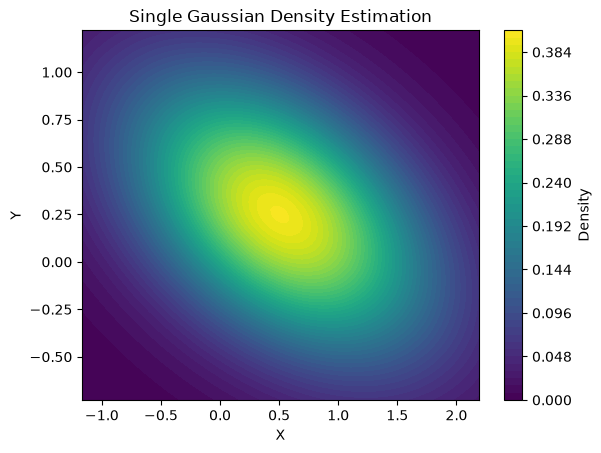

In [192]:
single_gaussian_model = single_Gaussian()
single_gaussian_model.fit(data)
single_gaussian_model.plot_gaussian()

In [193]:
n = 1000
gamma = 1.0
Y = data[np.random.choice(data.shape[0], n, replace=False)]


mmd_se_gaussian = MMD_squared(single_gaussian_model.sample(n), Y, kernel='se', gamma=gamma)
mmd_imq_gaussian = MMD_squared(single_gaussian_model.sample(n), Y, kernel='imq', gamma=gamma)

print(f"MMD^2 (Squared Exponential Kernel) for Single Gaussian: {mmd_se_gaussian}")
print(f"MMD^2 (Inverse Multiquadric Kernel) for Single Gaussian: {mmd_imq_gaussian}")

MMD^2 (Squared Exponential Kernel) for Single Gaussian: 0.01409673869096939
MMD^2 (Inverse Multiquadric Kernel) for Single Gaussian: 0.006029936646931189


In [194]:
class Gaussian_mixture_model:
    def __init__(self, n_components,data,iterations):
        self.n_components = n_components
        self.means = None
        self.cov = None
        self.weights = None
        self.data = data
        self.iterations = iterations


    def fit(self, data):
        #initialize means, covariances, and weights
        self.means = data[np.random.choice(data.shape[0], self.n_components, replace=False)]
        self.cov = np.array([np.eye(data.shape[1]) for _ in range(self.n_components)])
        self.weights = np.ones(self.n_components) / self.n_components

        #EM algorithm
        for _ in range(self.iterations):  # number of iterations
            #E-step
            responsibilities = np.zeros((data.shape[0], self.n_components))
            for k in range(self.n_components):
                diff = data - self.means[k]
                inv_cov = np.linalg.inv(self.cov[k])
                exponent = -0.5 * np.sum(diff @ inv_cov * diff, axis=1)
                normalization = 1 / (np.sqrt((2 * np.pi) ** data.shape[1] * np.linalg.det(self.cov[k])))
                responsibilities[:, k] = self.weights[k] * normalization * np.exp(exponent)
            responsibilities /= responsibilities.sum(axis=1, keepdims=True)

            #M-step
            Nk = responsibilities.sum(axis=0)
            self.means = (responsibilities.T @ data) / Nk[:, None]
            for k in range(self.n_components):
                diff = data - self.means[k]
                self.cov[k] = (responsibilities[:, k][:, None] * diff).T @ diff / Nk[k]
            self.weights = Nk / data.shape[0]

    def sample(self, n_samples):
        samples = []
        component_choices = np.random.choice(self.n_components, size=n_samples, p=self.weights)
        for k in range(self.n_components):
            n_k = np.sum(component_choices == k)
            if n_k > 0:
                samples_k = np.random.multivariate_normal(self.means[k], self.cov[k], n_k)
                samples.append(samples_k)
        return np.vstack(samples)

    def score_samples(self, data):
        density = np.zeros(data.shape[0])
        for k in range(self.n_components):
            diff = data - self.means[k]
            inv_cov = np.linalg.inv(self.cov[k]) + np.eye(data.shape[1]) * 1e-6  # Add a small value to the diagonal for numerical stability
            exponent = -0.5 * np.sum(diff @ inv_cov * diff, axis=1)
            normalization = 1 / (np.sqrt((2 * np.pi) ** data.shape[1] * np.linalg.det(self.cov[k])))
            density += self.weights[k] * normalization * np.exp(exponent)
        return density

    def plot_gaussian_mixture(self):
        x = np.linspace(np.min(self.data[:, 0]), np.max(self.data[:, 0]), 100)
        y = np.linspace(np.min(self.data[:, 1]), np.max(self.data[:, 1]), 100)
        X, Y = np.meshgrid(x, y)
        pos = np.dstack((X, Y))
        Z = self.score_samples(pos.reshape(-1, 2)).reshape(X.shape)

        plt.contourf(X, Y, Z, levels=50, cmap='viridis')
        plt.colorbar(label='Density')
        plt.xlabel('X')
        plt.ylabel('Y')
        plt.title('Gaussian Mixture Model Density Estimation')
        plt.show()

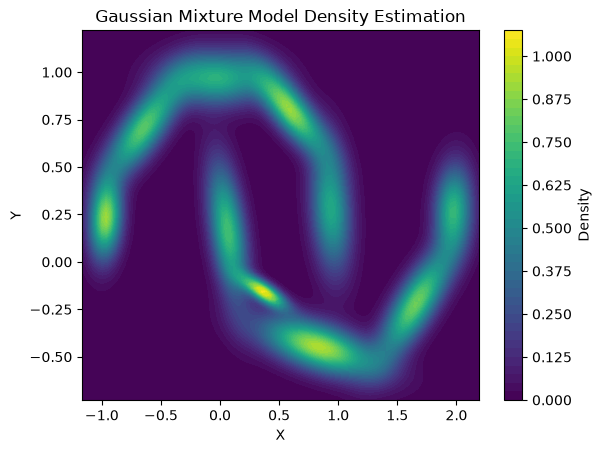

In [195]:
gaussian_mixture_model = Gaussian_mixture_model(n_components=10,data=data,iterations=5000)
gaussian_mixture_model.fit(data)
gaussian_mixture_model.plot_gaussian_mixture()

In [196]:
class kernel_density_estimation:
    def __init__(self, bandwidth):
        self.bandwidth = bandwidth

    def fit(self, data):
        self.data = data

    def sample(self, n_samples, random_state=None):
        rng = np.random.default_rng(random_state)
        indices = rng.integers(0, self.data.shape[0], size=n_samples)
        centers = self.data[indices]
        noise = rng.normal(0.0, self.bandwidth, size=centers.shape)
        return centers + noise

    def score_samples(self, data):
        diff = data[:, np.newaxis, :] - self.data[np.newaxis, :, :]
        kernel_values = np.exp(-0.5 * np.sum(diff ** 2, axis=2) / (self.bandwidth ** 2))
        dimension = self.data.shape[1]
        normalization = (2 * np.pi) ** (dimension / 2) * self.bandwidth ** dimension
        density = np.mean(kernel_values, axis=1) / normalization
        return density

    def plot_kde(self):
        x = np.linspace(np.min(self.data[:, 0]), np.max(self.data[:, 0]), 100)
        y = np.linspace(np.min(self.data[:, 1]), np.max(self.data[:, 1]), 100)
        X, Y = np.meshgrid(x, y)
        pos = np.dstack((X, Y))
        Z = self.score_samples(pos.reshape(-1, 2)).reshape(X.shape)

        plt.contourf(X, Y, Z, levels=50, cmap='viridis')
        plt.colorbar(label='Density')
        plt.xlabel('X')
        plt.ylabel('Y')
        plt.title('Kernel Density Estimation')
        plt.show()
        

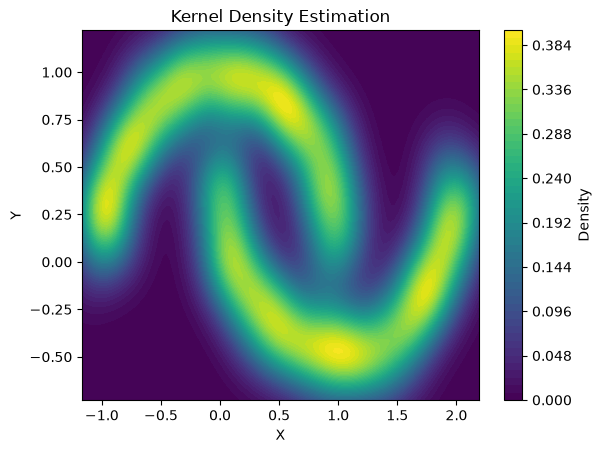

In [197]:
kernel_density_model = kernel_density_estimation(bandwidth=0.15)
kernel_density_model.fit(data)
kernel_density_model.plot_kde()

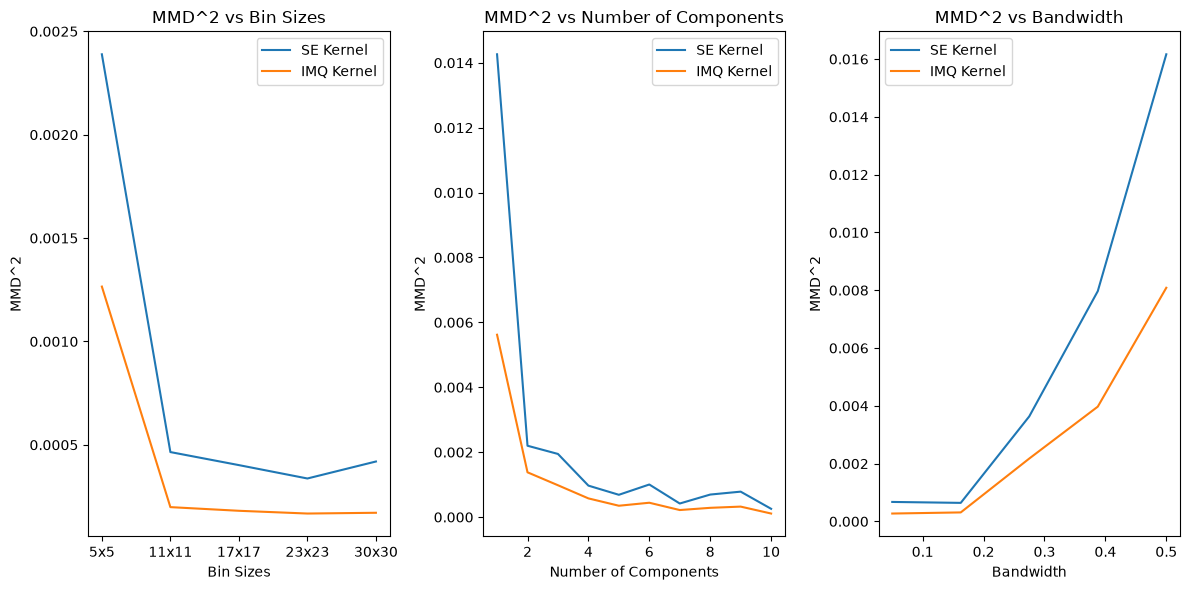

In [198]:
n = 1000
gamma = 1.0

#Sample from model
X_hist_data = Two_D_hist.sample(n)
X_gmm_data = gaussian_mixture_model.sample(n)
X_kde_data = kernel_density_model.sample(n)

#sample from data set
Y = data[np.random.choice(data.shape[0], n, replace=False)]

#caluclate MMD^2 for each model
mmd_se_hist = MMD_squared(X_hist_data, Y, kernel='se', gamma=gamma)
mmd_imq_hist = MMD_squared(X_hist_data, Y, kernel='imq', gamma=gamma)
mmd_se_gmm = MMD_squared(X_gmm_data, Y, kernel='se', gamma=gamma)
mmd_imq_gmm = MMD_squared(X_gmm_data, Y, kernel='imq', gamma=gamma)
mmd_se_kde = MMD_squared(X_kde_data, Y, kernel='se', gamma=gamma)
mmd_imq_kde = MMD_squared(X_kde_data, Y, kernel='imq', gamma=gamma)

accuracy_hist = []
bin_sizes = np.linspace(5, 30, 5, dtype=int)

for x_bins, y_bins in zip(bin_sizes, bin_sizes):

    Two_D_hist = Two_D_histogram(x_bins, y_bins, uniform_sample=True)
    Two_D_hist.fit()
    Two_D_hist.sample(n)
    X_hist_data = Two_D_hist.sample(n)

    mmd_se = MMD_squared(X_hist_data, Y, kernel='se', gamma=gamma)
    mmd_imq = MMD_squared(X_hist_data, Y, kernel='imq', gamma=gamma)

    accuracy_hist.append((mmd_se, mmd_imq))



accuracy_gmm = []
component_counts = np.arange(1, 11)
for n_components in component_counts:
    gaussian_mixture_model = Gaussian_mixture_model(n_components=n_components, data=data, iterations=5000)
    gaussian_mixture_model.fit(data)
    X_gmm_data = gaussian_mixture_model.sample(n)

    mmd_se = MMD_squared(X_gmm_data, Y, kernel='se', gamma=gamma)
    mmd_imq = MMD_squared(X_gmm_data, Y, kernel='imq', gamma=gamma)

    accuracy_gmm.append((mmd_se, mmd_imq))

accuracy_kde = []
bandwidths = np.linspace(0.05, 0.5, 5)
for bandwidth in bandwidths:
    kernel_density_model = kernel_density_estimation(bandwidth=bandwidth)
    kernel_density_model.fit(data)
    X_kde_data = kernel_density_model.sample(n)

    mmd_se = MMD_squared(X_kde_data, Y, kernel='se', gamma=gamma)
    mmd_imq = MMD_squared(X_kde_data, Y, kernel='imq', gamma=gamma)

    accuracy_kde.append((mmd_se, mmd_imq))

plt.figure(figsize=(12, 6))
plt.subplot(1, 3, 1)
plt.plot([f"{x}x{y}" for x, y in zip(bin_sizes, bin_sizes)], [acc[0] for acc in accuracy_hist], label='SE Kernel')
plt.plot([f"{x}x{y}" for x, y in zip(bin_sizes, bin_sizes)], [acc[1] for acc in accuracy_hist], label='IMQ Kernel')
plt.xlabel('Bin Sizes')
plt.ylabel('MMD^2')
plt.title('MMD^2 vs Bin Sizes')
plt.legend()    

plt.subplot(1, 3, 2)
plt.plot(component_counts, [acc[0] for acc in accuracy_gmm], label='SE Kernel')
plt.plot(component_counts, [acc[1] for acc in accuracy_gmm], label='IMQ Kernel')
plt.xlabel('Number of Components')
plt.ylabel('MMD^2')
plt.title('MMD^2 vs Number of Components')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(bandwidths, [acc[0] for acc in accuracy_kde], label='SE Kernel')
plt.plot(bandwidths, [acc[1] for acc in accuracy_kde], label='IMQ Kernel')
plt.xlabel('Bandwidth')
plt.ylabel('MMD^2')
plt.title('MMD^2 vs Bandwidth')
plt.legend()

plt.tight_layout()
plt.show()